# Churn model comparison

Source: Chen (2012), Online Retail II, UCI, CC BY 4.0. Run the pipeline before this notebook. Figures describe historical purchases, not loyalty membership or causal offer effects.

In [1]:
from pathlib import Path
import json, pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd() if (Path.cwd()/'configs').exists() else Path.cwd().parent
plt.style.use('seaborn-v0_8-whitegrid')


In [2]:
from loyalty_ml.train_churn import train
from loyalty_ml.features import FEATURES
from loyalty_ml.evaluate import churn_metrics
x=pd.read_parquet(ROOT/'data/processed/customer_snapshots.parquet')
training=x[x.snapshot_date<'2011-06-01'];validation=x[x.snapshot_date=='2011-06-01'];test=x[x.snapshot_date=='2011-09-01']
model,name,validation_results=train(training,validation)
pd.Series(validation_results,name='Validation PR-AUC')

logistic_regression    0.704371
lightgbm               0.702187
Name: Validation PR-AUC, dtype: float64

In [3]:
pred=model.predict_proba(test[FEATURES])[:,1]
pd.Series(churn_metrics(test.inactive_90,pred),name='Test metrics')

pr_auc            0.596905
roc_auc           0.735012
brier             0.215601
prevalence        0.393064
lift_top_10pct    1.726694
Name: Test metrics, dtype: float64

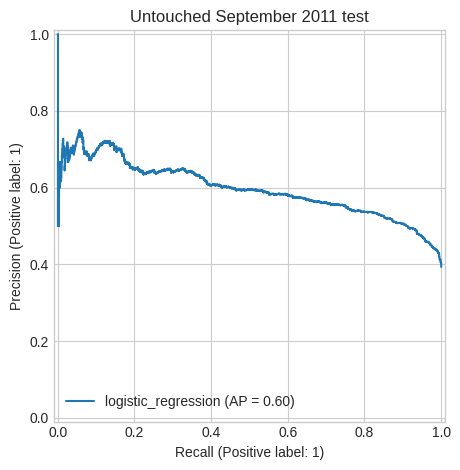

In [4]:
from sklearn.metrics import PrecisionRecallDisplay
PrecisionRecallDisplay.from_predictions(test.inactive_90,pred,name=name)
plt.title('Untouched September 2011 test');plt.tight_layout();plt.show()

## Interpretation
Compare against the baseline and report limitations. No purchase for 90 days does not prove permanent churn. Large wholesale purchases can dominate spending error. Survival diagnostics can reject proportional hazards; the Cox model is exploratory if that assumption fails. Retention priority is a heuristic requiring an experiment before claiming campaign benefit.